# COM7022 Machine Learning — Revised Practical Clustering Project

**Assessment:** Task 1 — Practical Project (Python notebook)  
**Data:** `Sales-[5444].csv`
**Student ID:**   
**Scope:** Updated version of the originally submitted notebook; the original exploratory analysis and three clustering methods are retained and extended in response to the lecturer's feedback.

**What this notebook addresses:** data quality and sales-count discrepancies; missing-data and outlier choices; one-hot-encoding/feature-selection sensitivity; separately explained K-Means, Ward Hierarchical Clustering and DBSCAN; cluster-count trade-offs; repeated-sample stability; numerical cluster profiles; and measurable proposed business KPIs.

**Important submission boundary:** The professor also requests a separate **3,000-word written report covering Task 1 and Task 2**, a **published accessible GitHub repository**, and a **genuine Turnitin report**. Completing this notebook does not itself provide those separate deliverables. Only publish the original CSV if permission/licensing allows. All *observed* results below come from the uploaded data; operational KPI targets are explicitly marked as proposals.

## 1. Assessment objectives and analysis plan

The brief requires the analysis to be completed in Python. It asks for dataset preparation, justified feature selection, multiple clustering methods, appropriate transformation of numeric and categorical variables, PCA where useful, evaluation and comparison of models, justified final-model selection, cluster interpretation and business relevance.

This notebook follows that sequence:

1. Inspect the supplied CSV and document data quality.
2. Clean category labels and define a defensible feature set.
3. Impute missing numeric values, reduce numeric skew, scale numeric features and one-hot encode category groups.
4. Explore PCA as a visualisation aid.
5. Compare K-Means and agglomerative hierarchical clustering across a range of cluster counts.
6. Tune DBSCAN and explicitly report how much data it treats as noise.
7. Compare results using internal validation metrics and practical considerations.
8. Profile clusters using the original, interpretable data fields.
9. Quantify sensitivity to imputation, outliers, numerical/categorical features and cluster count.
10. Evaluate K-Means membership stability across repeated 80% samples.
11. Summarise limitations and propose business actions with measurable KPIs.

**Important distinction:** clustering is unsupervised learning. There is no known target label in this dataset, so validation uses internal clustering measures and interpretation of the resulting groups, not classification accuracy.

## 2. Import libraries and set reproducible options

The analysis uses pandas and NumPy for data handling; scikit-learn for preprocessing, clustering, PCA and validation; and Matplotlib/Seaborn for visualisation. A fixed random seed makes the K-Means results reproducible.

In [27]:
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, RobustScaler, FunctionTransformer
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 80)
sns.set_theme(style="whitegrid", context="notebook")

print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Analysis setup complete.")

pandas: 2.2.3
NumPy: 2.4.6
Analysis setup complete.


## 3. Load the exact supplied dataset

Place the CSV file `Sales-[5444].csv` in the working directory before running the notebook.

In [28]:
DATA_FILENAMES = ["Sales-[5444].csv"]
search_folders = [Path.cwd(), Path('/mnt/data')]
possible_paths = [folder / name for folder in search_folders for name in DATA_FILENAMES]
DATA_PATH = next((p for p in possible_paths if p.is_file()), None)
if DATA_PATH is None:
        raise FileNotFoundError(
        "Dataset not found. Place 'Sales-[5444].csv' beside the notebook, then rerun."
    )
df_raw = pd.read_csv(DATA_PATH)
print(f"Loaded: {DATA_PATH.resolve()}")
print(f"Dataset shape: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
assert {'price','available','sold','Catatory','text'}.issubset(df_raw.columns)
display(df_raw.head())

Loaded: /content/Sales-[5444].csv
Dataset shape: 1,000 rows × 10 columns


,Item_Name,details,Catatory,price,priceWithCurrency,available,text,sold,lastUpdated,itemLocation
0,Dior,Christian Dior Sauvage Men's EDP 3.4 oz Fragrance Spray,Eau de Parfum,84.99,US $84.99/ea,10.0,More than 10 available / 116 sold,NaN,"May 24, 2024 10:03:04 PDT","Allen Park, Michigan, United States"
1,AS SHOW,A-v-entus Eau de Parfum 3.3 oz 100ML Millesime EDP Col-ogne for Men New In Box,Eau de Parfum,NaN,US $109.99,8.0,8 available / 48 sold,48.0,"May 23, 2024 23:07:49 PDT","Atlanta, Georgia, Canada"
2,Unbranded,HOGO BOSS cologne For Men 3.4 oz,Eau de Toilette,100.00,US $100.00,10.0,More than 10 available / 27 sold,27.0,"May 22, 2024 21:55:43 PDT","Dearborn, Michigan, United States"
3,Giorgio Armani,Acqua Di Gio by Giorgio Armani 6.7 Fl oz Eau De Toilette Spray Men' New & Se...,Eau de Toilette,NaN,US $44.99/ea,2.0,2 available / 159 sold,159.0,"May 24, 2024 03:30:43 PDT","Reinholds, Pennsylvania, United States"
4,Lattafa,Lattafa Men's Hayaati Al Maleky EDP Spray 3.4 oz Fragrances 6291108734056,Fragrances,16.91,NaN,NaN,Limited quantity available / 156 sold,NaN,"May 24, 2024 07:56:25 PDT","Brooklyn, New York, United States"


## 4. Initial data exploration

The unit of analysis is one product listing/record. First inspect column names, data types, summary statistics and exact duplicate rows. Repeated descriptions do not automatically mean a record is a duplicate; separate sellers may list the same product.

In [29]:
print("Column names:")
print(df_raw.columns.tolist())
print("\nData types and non-null counts:")
display(pd.DataFrame({
    "data_type": df_raw.dtypes.astype(str),
    "non_missing": df_raw.notna().sum(),
    "missing": df_raw.isna().sum(),
}))
print(f"\nExact duplicate rows: {df_raw.duplicated().sum()}")
print("\nNumeric summary:")
display(df_raw[["price", "available", "sold"]].describe().T)

Column names:
['Item_Name', 'details', 'Catatory', 'price', 'priceWithCurrency', 'available', 'text', 'sold', 'lastUpdated', 'itemLocation']

Data types and non-null counts:


,data_type,non_missing,missing
Item_Name,object,999,1
details,object,1000,0
Catatory,object,997,3
price,float64,995,5
priceWithCurrency,object,999,1
available,float64,889,111
text,object,997,3
sold,float64,992,8
lastUpdated,object,947,53
itemLocation,object,1000,0



Exact duplicate rows: 0

Numeric summary:


,count,mean,std,min,25%,50%,75%,max
price,995.0,46.433467,35.551712,3.0,22.99,35.71,59.00,259.09
available,889.0,20.046119,61.547985,2.0,5.00,10.00,10.00,842.00
sold,992.0,775.246976,3211.433298,1.0,14.00,49.50,324.75,54052.00


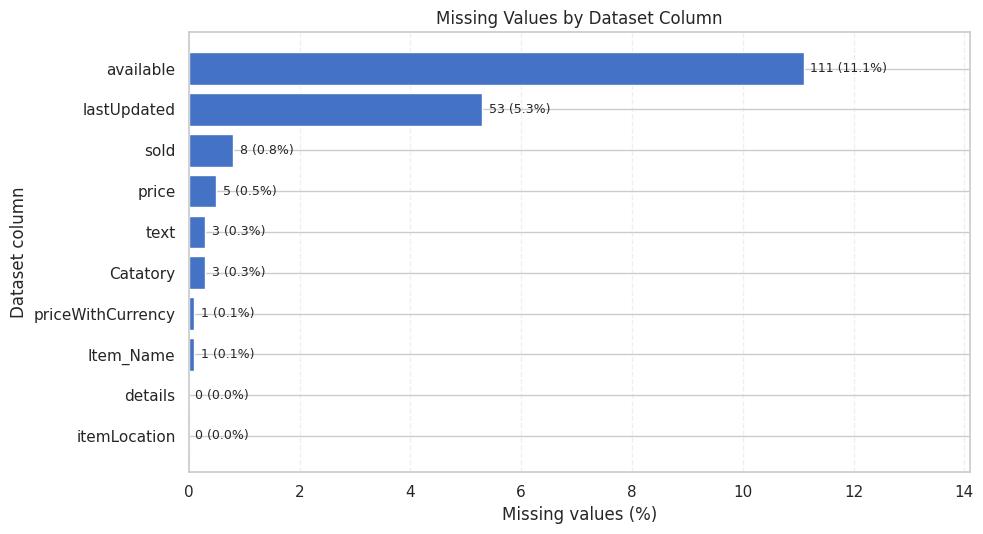

In [30]:
# Sort the missing-value summary from highest to lowest
missing_summary = pd.DataFrame({
    "missing_count": df_raw.isna().sum(),
    "missing_percent": df_raw.isna().mean() * 100
})
missing_summary = missing_summary.sort_values(
    "missing_count", ascending=False
)

# Create a horizontal bar chart
fig, ax = plt.subplots(figsize=(10, 5.5))

bars = ax.barh(
    missing_summary.index.astype(str),
    missing_summary["missing_percent"],
    color="#4472C4"
)

# Put the highest missing percentage at the top
ax.invert_yaxis()

# Display the count and percentage beside every bar
for i, (count, percent) in enumerate(zip(
    missing_summary["missing_count"],
    missing_summary["missing_percent"]
)):
    ax.text(
        percent + 0.12,
        i,
        f"{int(count)} ({percent:.1f}%)",
        va="center",
        fontsize=9
    )

# Format the chart
ax.set_title("Missing Values by Dataset Column")
ax.set_xlabel("Missing values (%)")
ax.set_ylabel("Dataset column")
ax.set_xlim(0, missing_summary["missing_percent"].max() + 3)
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


### Initial data-quality interpretation

The supplied file contains 1,000 rows and 10 columns. Several columns have missing values, particularly `available`. `price`, `available` and `sold` are numeric but have very different ranges and right-skewed distributions. The high-cardinality text fields and timestamp are not included directly in the baseline distance calculation because doing so would require additional text/date feature engineering and could make distances harder to interpret. Their exclusion is a modelling decision, not a claim that they are never useful.

## 5. Investigate data quality, categorical labels and possible inconsistencies

The `Catatory` column name is retained as supplied, but its values are normalised for consistent casing and a small number of clear spelling/abbreviation variants. The `text` column appears to repeat availability and sold-count information in human-readable form. It is used only as a data-quality check, not as a second copy of the numeric features.

In [31]:
# Compare numeric sold counts against the count stated in the text field when that count can be parsed.
quality_check = df_raw.copy()
text_sold = (
    quality_check["text"].astype("string")
    .str.extract(r"([\d,]+)\s*sold\b", flags=re.IGNORECASE, expand=False)
    .str.replace(",", "", regex=False)
)
quality_check["sold_in_text"] = pd.to_numeric(text_sold, errors="coerce")
quality_check["sold_numeric"] = pd.to_numeric(quality_check["sold"], errors="coerce")
comparable = quality_check["sold_in_text"].notna() & quality_check["sold_numeric"].notna()
quality_check["sold_text_mismatch"] = False
quality_check.loc[comparable, "sold_text_mismatch"] = (
    quality_check.loc[comparable, "sold_in_text"].round().astype("int64")
    != quality_check.loc[comparable, "sold_numeric"].round().astype("int64")
)

print(f"Records where both sold values could be compared: {int(comparable.sum())}")
print(f"Potential sold-count mismatches: {int(quality_check['sold_text_mismatch'].sum())}")
if quality_check["sold_text_mismatch"].any():
    display(quality_check.loc[quality_check["sold_text_mismatch"],
                              ["Item_Name", "text", "sold", "sold_in_text"]].head(10))
else:
    print("No sold-count mismatches detected by this simple text comparison.")

Records where both sold values could be compared: 992
Potential sold-count mismatches: 1


,Item_Name,text,sold,sold_in_text
7,Unbranded,Last One / 6 sold,7654.0,6


In [32]:
# Identify statistical outliers with the IQR rule for investigation only; do not automatically delete them.
outlier_rows = []
for col in ["price", "available", "sold"]:
    values = pd.to_numeric(df_raw[col], errors="coerce").dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outlier_rows.append({
        "feature": col,
        "q1": q1,
        "q3": q3,
        "IQR_lower_fence": lower,
        "IQR_upper_fence": upper,
        "values_outside_fences": int(((values < lower) | (values > upper)).sum()),
        "maximum": values.max(),
    })
display(pd.DataFrame(outlier_rows).round(2))

print("IQR flags are diagnostic only. Extreme sales/stock values may be real listings and are not removed automatically.")

,feature,q1,q3,IQR_lower_fence,IQR_upper_fence,values_outside_fences,maximum
0,price,22.99,59.00,-31.03,113.02,54,259.09
1,available,5.00,10.00,-2.50,17.50,101,842.00
2,sold,14.00,324.75,-452.12,790.88,136,54052.00


IQR flags are diagnostic only. Extreme sales/stock values may be real listings and are not removed automatically.


## 6. Clean the category field and define the modelling features

### Feature selection rationale

- **`price`** is a numeric product characteristic and may distinguish price segments.
- **`available`** represents recorded inventory quantity and may help identify inventory profiles.
- **`sold`** represents the supplied cumulative sold count. The data does not specify the time window, so it must not be interpreted as weekly/monthly sales velocity.
- **Cleaned `Catatory`** provides broad product-type information. To avoid dozens of rare category levels creating a sparse, high-cardinality encoding, categories with fewer than 20 records are grouped as `Other / rare`; missing category entries are kept as `Unknown / missing`.

The formatted `priceWithCurrency` field duplicates `price` and is excluded. The text field overlaps with `available` and `sold`, so it is not included as another feature. `Item_Name`, `details`, `lastUpdated` and `itemLocation` are excluded from the baseline distance calculation because they are high-cardinality text, timestamp or location fields that would need separate, justified engineering. This keeps the baseline model interpretable and avoids double-counting duplicated information. These exclusions can be tested in future work.

In [33]:
required_columns = ["price", "available", "sold", "Catatory"]
missing_columns = [c for c in required_columns if c not in df_raw.columns]
if missing_columns:
    raise KeyError(f"Expected column(s) not found: {missing_columns}")

# Convert the numeric columns defensively; unparseable entries become missing and will be imputed.
work = df_raw.copy()
for col in ["price", "available", "sold"]:
    work[col] = pd.to_numeric(work[col], errors="coerce")

# log1p is only valid for non-negative values. Check this assumption explicitly.
negative_counts = (work[["price", "available", "sold"]] < 0).sum()
display(negative_counts.rename("negative_values").to_frame())
if (work[["price", "available", "sold"]].lt(0).any().any()):
    raise ValueError("Negative values detected in a field to be log-transformed. Investigate before proceeding.")

def normalise_category(value):
    """Standardise casing/spacing and a small number of clear label variants."""
    if pd.isna(value) or str(value).strip() == "":
        return "Unknown / missing"
    label = " ".join(str(value).strip().casefold().split())
    clear_variants = {
        "eau de toillette": "eau de toilette",  # obvious spelling variant
        "edt": "eau de toilette",               # common abbreviation
        "eau de perfume": "eau de parfum",      # common variant spelling
        "edp": "eau de parfum",                # common abbreviation
    }
    label = clear_variants.get(label, label)
    if label == "unknown / missing":
        return "Unknown / missing"
    return label.title()

work["category_clean"] = work["Catatory"].map(normalise_category)
category_counts = work["category_clean"].value_counts(dropna=False)
frequent_categories = set(category_counts[category_counts >= 20].index)
frequent_categories.discard("Unknown / missing")

work["cluster_category"] = work["category_clean"].apply(
    lambda label: "Unknown / missing" if label == "Unknown / missing"
    else (label if label in frequent_categories else "Other / rare")
)

print("Most common cleaned category labels:")
display(category_counts.head(12).rename_axis("category").reset_index(name="records"))
print("Category groups used in the clustering features:")
display(work["cluster_category"].value_counts().rename_axis("category_group").reset_index(name="records"))

numeric_features = ["price", "available", "sold"]
categorical_features = ["cluster_category"]
model_input = work[numeric_features + categorical_features].copy()
print(f"Rows retained for modelling: {len(model_input):,} of {len(work):,}")

,negative_values
price,0
available,0
sold,0


Most common cleaned category labels:


,category,records
0,Eau De Toilette,459
1,Eau De Parfum,310
2,Eau De Cologne,57
3,Perfume,50
4,Fragrances,32
5,Parfum,17
6,Cologne,6
7,Gift Sets,6
8,Body Spray,4
9,Le Parfum,3


Category groups used in the clustering features:


,category_group,records
0,Eau De Toilette,459
1,Eau De Parfum,310
2,Other / rare,89
3,Eau De Cologne,57
4,Perfume,50
5,Fragrances,32
6,Unknown / missing,3


Rows retained for modelling: 1,000 of 1,000


## 7. Preprocess variables for distance-based clustering

The median is used for each missing numeric feature because the distributions are strongly right-skewed and the median is less affected by extreme values than the mean. Missingness is not demonstrably random; imputation **does not** restore unknown values and can make imputed records artificially similar. The `available` column has especially substantial missingness, so stock-based interpretation must be cautious.

Non-negative numerical features (`price`, `available`, `sold`) undergo `log1p`, which compresses the influence of very large counts while retaining zeros, followed by `RobustScaler` (centering on the median and scaling by IQR). Robust scaling **does not eliminate** outlier effects. Categories are one-hot encoded; this avoids artificial ordinal meaning but affects Euclidean distance: two distinct one-hot categories have squared categorical distance **2**, regardless of their semantic similarity. Consequently, category dummies can drive distance-based cluster membership. The additional experiments in section 14 test these assumptions rather than presuming they are harmless.

All three original algorithm comparisons use the **same baseline feature matrix**, while the later sensitivity tests deliberately change one modelling choice at a time. Original-unit profiles use observed values, not filled-in values.

In [34]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("scaler", RobustScaler()),
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("category", categorical_pipeline, categorical_features),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)

X = preprocessor.fit_transform(model_input)
feature_names = preprocessor.get_feature_names_out()
X_model = pd.DataFrame(X, columns=feature_names, index=work.index)

print("Model matrix shape:", X_model.shape)
print("All values finite:", bool(np.isfinite(X).all()))
print("Transformed features:")
print(list(feature_names))
display(X_model.head())

Model matrix shape: (1000, 10)
All values finite: True
Transformed features:
['price', 'available', 'sold', 'cluster_category_Eau De Cologne', 'cluster_category_Eau De Parfum', 'cluster_category_Eau De Toilette', 'cluster_category_Fragrances', 'cluster_category_Other / rare', 'cluster_category_Perfume', 'cluster_category_Unknown / missing']


,price,available,sold,cluster_category_Eau De Cologne,cluster_category_Eau De Parfum,cluster_category_Eau De Toilette,cluster_category_Fragrances,cluster_category_Other / rare,cluster_category_Perfume,cluster_category_Unknown / missing
0,0.928647,0.000000,0.000000,0.0,1.0,0.0,0.0,0.0,0.0,0.0
1,0.000000,-0.331066,-0.009868,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,1.104179,0.000000,-0.193016,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,0.000000,-2.143551,0.377413,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,-0.783006,0.000000,0.000000,0.0,0.0,0.0,1.0,0.0,0.0,0.0


## 8. PCA for dimensionality reduction and visualisation

Principal Component Analysis (PCA) creates new axes that capture variation in the transformed features. Here it is used primarily to visualise the data in two dimensions. The main clustering models are fitted on the preprocessed feature matrix `X`, not the two-dimensional PCA projection; this avoids losing information solely for plotting. The PCA scatter plot is a simplified view and cannot establish cluster quality by itself.

,principal_component,explained_variance_ratio,cumulative_explained_variance
0,PC1,0.5786,0.5786
1,PC2,0.1519,0.7305
2,PC3,0.1099,0.8404
3,PC4,0.0789,0.9193
4,PC5,0.0364,0.9557
5,PC6,0.0194,0.9751
6,PC7,0.0145,0.9896
7,PC8,0.0095,0.9990
8,PC9,0.0010,1.0000
9,PC10,0.0000,1.0000


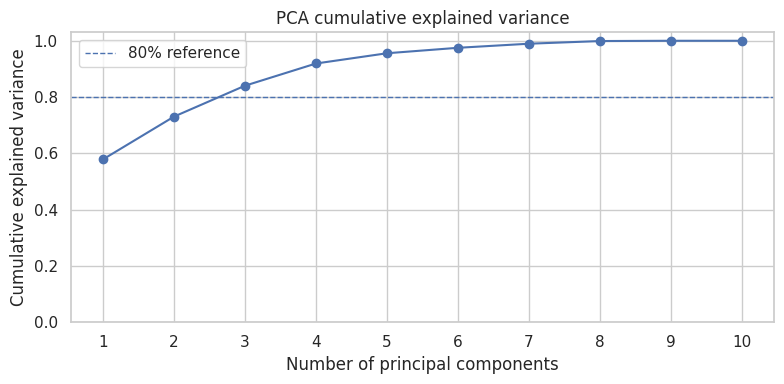

Variance explained by PC1 and PC2 combined: 73.0%


In [35]:
pca_all = PCA()
pca_all.fit(X)
explained = pca_all.explained_variance_ratio_
pca_variance = pd.DataFrame({
    "principal_component": [f"PC{i+1}" for i in range(len(explained))],
    "explained_variance_ratio": explained,
    "cumulative_explained_variance": np.cumsum(explained),
})
display(pca_variance.round(4))

plt.figure(figsize=(8, 4))
components = np.arange(1, len(explained) + 1)
plt.plot(components, np.cumsum(explained), marker="o")
plt.axhline(0.80, linestyle="--", linewidth=1, label="80% reference")
plt.xticks(components)
plt.ylim(0, 1.03)
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA cumulative explained variance")
plt.legend()
plt.tight_layout()
plt.show()

pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca_2d = pca_2d.fit_transform(X)
print("Variance explained by PC1 and PC2 combined:", f"{pca_2d.explained_variance_ratio_.sum():.1%}")

## 9. Model 1 — K-Means clustering

**How it works.** K-Means partitions all observations into a chosen number `k` of groups by alternating (i) assigning each product to its nearest cluster centroid and (ii) updating each centroid to the mean of its assigned observations. This process aims to minimise **within-cluster squared Euclidean distance** (inertia), and converges to a local optimum rather than guaranteeing a global optimum. Multiple initialisations (`n_init=20`), `max_iter=500`, and a fixed `random_state=42` reduce random-start variability.

**How applied.** The baseline matrix combines three imputed/log-transformed/robust-scaled numerical columns with one-hot-encoded category groups. We evaluate every `k` from 2 through 10 and report inertia, Silhouette (higher is generally better), Davies–Bouldin (lower is better) and Calinski–Harabasz (higher is better). The two-cluster solution in the supplied analysis achieves approximately **0.5322 Silhouette** but is very uneven (909 versus 91 observations). Thus, a good geometric score does not by itself establish sufficient operational detail. The later granularity and resampling tests assess this explicitly.

**Advantages and weaknesses.** It assigns all products and produces comprehensible profiles; however, it presumes broadly spherical/centroid-based groups, depends on scale and outliers, and forces all observations into clusters. See the detailed sensitivity tests in section 14.

In [36]:
kmeans_results = []
kmeans_models = {}
kmeans_labels = {}

for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20, max_iter=500)
    labels = model.fit_predict(X)
    kmeans_models[k] = model
    kmeans_labels[k] = labels
    kmeans_results.append({
        "model": "K-Means",
        "k": k,
        "clusters": len(np.unique(labels)),
        "inertia": model.inertia_,
        "silhouette": silhouette_score(X, labels),
        "davies_bouldin": davies_bouldin_score(X, labels),
        "calinski_harabasz": calinski_harabasz_score(X, labels),
        "noise_percent": 0.0,
    })

kmeans_results_df = pd.DataFrame(kmeans_results)
display(kmeans_results_df.round(4))
best_k_silhouette = int(kmeans_results_df.loc[kmeans_results_df["silhouette"].idxmax(), "k"])
print(f"Highest K-Means Silhouette score in the tested range: k={best_k_silhouette}")

,model,k,clusters,inertia,silhouette,davies_bouldin,calinski_harabasz,noise_percent
0,K-Means,2,2,2273.9776,0.5322,0.7425,593.5327,0.0
1,K-Means,3,3,1814.6787,0.2544,1.3348,497.6773,0.0
2,K-Means,4,4,1540.8533,0.2378,1.3257,449.3543,0.0
3,K-Means,5,5,1347.3753,0.2640,1.2566,420.7425,0.0
4,K-Means,6,6,1230.7012,0.2580,1.2460,386.9806,0.0
5,K-Means,7,7,1121.6459,0.2365,1.1745,369.5735,0.0
6,K-Means,8,8,1048.4003,0.2344,1.2859,348.4681,0.0
7,K-Means,9,9,980.3711,0.2482,1.2826,334.3348,0.0
8,K-Means,10,10,926.0390,0.2500,1.2928,320.7592,0.0


Highest K-Means Silhouette score in the tested range: k=2


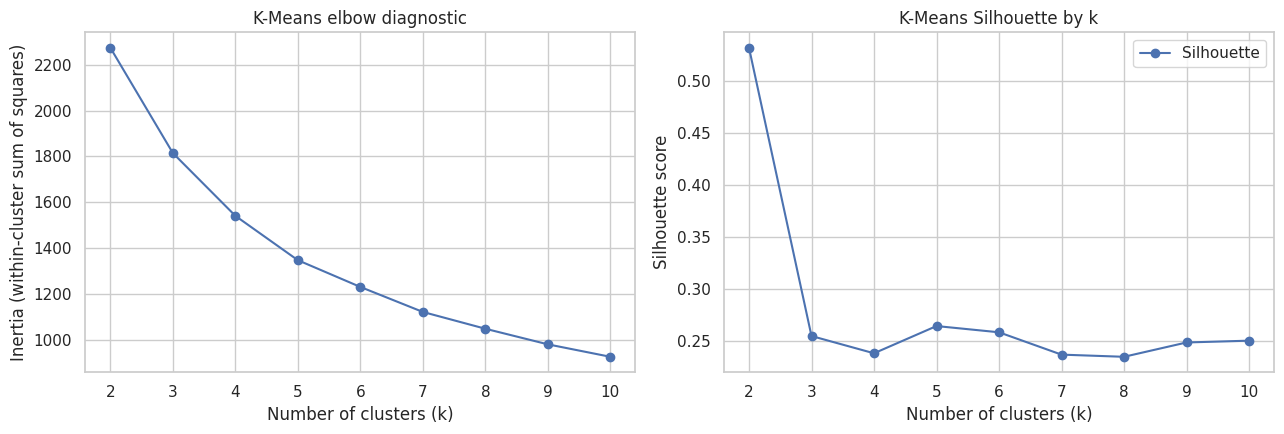

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(kmeans_results_df["k"], kmeans_results_df["inertia"], marker="o")
axes[0].set_title("K-Means elbow diagnostic")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia (within-cluster sum of squares)")
axes[0].set_xticks(kmeans_results_df["k"])

axes[1].plot(kmeans_results_df["k"], kmeans_results_df["silhouette"], marker="o", label="Silhouette")
axes[1].set_title("K-Means Silhouette by k")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score")
axes[1].set_xticks(kmeans_results_df["k"])
axes[1].legend()
plt.tight_layout()
plt.show()

### K-Means interpretation

Inertia normally decreases as more clusters are added, so it should not be minimised without considering model complexity. The Silhouette score is maximised at the reported `k` within the tested range, but the highest score is only a starting point for selection. A small number of broad clusters may score well yet give limited business detail; a larger number of clusters may be more actionable but less cleanly separated.

## 10. Model 2 — Agglomerative Hierarchical Clustering (Ward linkage)

**How it works.** Agglomerative clustering starts with individual observations and merges the most compatible clusters step by step. Ward's linkage chooses each merge to minimise the increase in within-cluster squared variation; it therefore tends to produce compact groups. Unlike K-Means, it builds a merge hierarchy rather than iteratively reassigning points to centroids. It is usually more computationally demanding for large datasets.

**How applied.** We apply Ward linkage to **the same baseline transformed input matrix** and test `k=2` to `k=10` with the same three internal metrics. The two-group Ward solution yields approximately **0.5250 Silhouette**, slightly below K-Means' **0.5322**. The gap is small and does **not** establish statistical superiority for K-Means. Both methods produce a two-cluster preferred count under the baseline score, but they share sensitivity to feature scaling and to large values. Results must be compared by both fit and business interpretation.

In [38]:
hierarchical_results = []
hierarchical_models = {}
hierarchical_labels = {}

for k in range(2, 11):
    model = AgglomerativeClustering(n_clusters=k, linkage="ward")
    labels = model.fit_predict(X)
    hierarchical_models[k] = model
    hierarchical_labels[k] = labels
    hierarchical_results.append({
        "model": "Hierarchical (Ward)",
        "k": k,
        "clusters": len(np.unique(labels)),
        "silhouette": silhouette_score(X, labels),
        "davies_bouldin": davies_bouldin_score(X, labels),
        "calinski_harabasz": calinski_harabasz_score(X, labels),
        "noise_percent": 0.0,
    })

hierarchical_results_df = pd.DataFrame(hierarchical_results)
display(hierarchical_results_df.round(4))
best_hierarchical_k = int(hierarchical_results_df.loc[hierarchical_results_df["silhouette"].idxmax(), "k"])
print(f"Highest Hierarchical Silhouette score in the tested range: k={best_hierarchical_k}")

,model,k,clusters,silhouette,davies_bouldin,calinski_harabasz,noise_percent
0,Hierarchical (Ward),2,2,0.5250,0.7544,587.0202,0.0
1,Hierarchical (Ward),3,3,0.2148,1.4971,453.4141,0.0
2,Hierarchical (Ward),4,4,0.2051,1.5405,385.8809,0.0
3,Hierarchical (Ward),5,5,0.2149,1.3392,356.7379,0.0
4,Hierarchical (Ward),6,6,0.2239,1.3923,329.3776,0.0
5,Hierarchical (Ward),7,7,0.2187,1.3931,317.9044,0.0
6,Hierarchical (Ward),8,8,0.1923,1.3776,300.0322,0.0
7,Hierarchical (Ward),9,9,0.1942,1.4121,285.4088,0.0
8,Hierarchical (Ward),10,10,0.2105,1.4133,273.6204,0.0


Highest Hierarchical Silhouette score in the tested range: k=2


## 11. Model 3 — DBSCAN (density-based clustering)

**How it works.** DBSCAN defines a neighbourhood radius `eps` and the minimum number of neighbouring observations `min_samples` needed for a **core** point. It connects density-reachable core and boundary observations into clusters. Observations outside those regions are marked **noise** (`-1`), rather than forced into a centroid group. It can find non-spherical clusters but is sensitive to distance scaling, heterogeneous densities and the chosen parameters.

**How applied.** The code evaluates eight `eps` values from **0.50 to 1.75** and `min_samples` of **5, 10 and 15** using the baseline transformed dataset and Euclidean metric. The selected comparison setting (`eps=0.50`, `min_samples=15`) identifies **four** non-noise clusters from **573** records and flags **42.7%** as noise. The non-noise Silhouette is about **0.3190**. This may be useful to triage unusual listings, but excluding nearly half the products makes it a problematic standalone complete-segmentation solution.

**Critical metric caveat.** DBSCAN's Silhouette, Davies–Bouldin and Calinski–Harabasz values are calculated **only on assigned (non-noise) records** where valid. Therefore they are not directly comparable with full-data metrics from K-Means and Ward clustering. The noise fraction is always reported next to the score.

In [39]:
dbscan_results = []
dbscan_models = {}
dbscan_labels = {}

eps_values = [0.50, 0.65, 0.75, 0.90, 1.00, 1.25, 1.50, 1.75]
min_samples_values = [5, 10, 15]

for eps in eps_values:
    for min_samples in min_samples_values:
        model = DBSCAN(eps=eps, min_samples=min_samples, metric="euclidean")
        labels = model.fit_predict(X)
        dbscan_models[(eps, min_samples)] = model
        dbscan_labels[(eps, min_samples)] = labels

        non_noise_mask = labels != -1
        non_noise_labels = labels[non_noise_mask]
        n_clusters = len(np.unique(non_noise_labels))
        n_non_noise = int(non_noise_mask.sum())
        noise_percent = float((~non_noise_mask).mean() * 100)

        silhouette = np.nan
        davies_bouldin = np.nan
        calinski_harabasz = np.nan
        # Metrics need at least 2 clusters and fewer clusters than evaluated records.
        if n_clusters >= 2 and n_non_noise > n_clusters:
            X_core = X[non_noise_mask]
            silhouette = silhouette_score(X_core, non_noise_labels)
            davies_bouldin = davies_bouldin_score(X_core, non_noise_labels)
            calinski_harabasz = calinski_harabasz_score(X_core, non_noise_labels)

        sizes = pd.Series(non_noise_labels).value_counts() if n_non_noise else pd.Series(dtype=int)
        dbscan_results.append({
            "model": "DBSCAN",
            "eps": eps,
            "min_samples": min_samples,
            "clusters_excluding_noise": n_clusters,
            "records_clustered": n_non_noise,
            "noise_percent": noise_percent,
            "smallest_cluster": int(sizes.min()) if len(sizes) else 0,
            "silhouette_non_noise": silhouette,
            "davies_bouldin_non_noise": davies_bouldin,
            "calinski_harabasz_non_noise": calinski_harabasz,
        })

dbscan_results_df = pd.DataFrame(dbscan_results)
display(dbscan_results_df.sort_values(
    ["silhouette_non_noise", "noise_percent"], ascending=[False, True], na_position="last"
).head(12).round(4))

# For a practical candidate, require at least two clusters and <=50% noise, then rank by inlier Silhouette.
dbscan_eligible = dbscan_results_df.loc[
    dbscan_results_df["silhouette_non_noise"].notna()
    & (dbscan_results_df["clusters_excluding_noise"] >= 2)
    & (dbscan_results_df["noise_percent"] <= 50)
].copy()
if dbscan_eligible.empty:
    dbscan_best_row = dbscan_results_df.loc[dbscan_results_df["silhouette_non_noise"].idxmax()]
    print("No DBSCAN setting met the <=50% noise threshold; best valid silhouette is reported with that limitation.")
else:
    dbscan_best_row = dbscan_eligible.sort_values(
        ["silhouette_non_noise", "noise_percent"], ascending=[False, True]
    ).iloc[0]

best_dbscan_key = (float(dbscan_best_row["eps"]), int(dbscan_best_row["min_samples"]))
print("Selected DBSCAN comparison setting:", best_dbscan_key)
print(f"Clusters excluding noise: {int(dbscan_best_row['clusters_excluding_noise'])}")
print(f"Records assigned to clusters: {int(dbscan_best_row['records_clustered'])} / {len(work)}")
print(f"Noise: {dbscan_best_row['noise_percent']:.1f}%")
print(f"Silhouette on non-noise records: {dbscan_best_row['silhouette_non_noise']:.3f}")

,model,eps,min_samples,clusters_excluding_noise,records_clustered,noise_percent,smallest_cluster,silhouette_non_noise,davies_bouldin_non_noise,calinski_harabasz_non_noise
2,DBSCAN,0.50,15,4,573,42.7,15,0.3190,0.9386,137.8824
5,DBSCAN,0.65,15,4,707,29.3,23,0.2507,1.0993,137.6086
1,DBSCAN,0.50,10,6,677,32.3,10,0.2414,0.9699,95.9760
11,DBSCAN,0.90,15,7,880,12.0,25,0.2294,1.1727,152.7571
7,DBSCAN,0.75,10,8,878,12.2,11,0.2280,1.1234,139.4542
0,DBSCAN,0.50,5,12,822,17.8,5,0.2243,0.9163,96.2058
4,DBSCAN,0.65,10,10,841,15.9,10,0.2213,0.9652,108.5386
8,DBSCAN,0.75,15,8,802,19.8,15,0.2146,0.9957,115.6587
17,DBSCAN,1.25,15,6,953,4.7,27,0.1740,1.5486,78.9573
14,DBSCAN,1.00,15,6,906,9.4,27,0.1581,1.4031,84.4917


Selected DBSCAN comparison setting: (0.5, 15)
Clusters excluding noise: 4
Records assigned to clusters: 573 / 1000
Noise: 42.7%
Silhouette on non-noise records: 0.319


## 12. Compare models and choose the most suitable approach

The table below compares the strongest tested K-Means and Hierarchical settings by full-data Silhouette score with the selected DBSCAN setting. For DBSCAN, its Silhouette score excludes noise records, so it must be interpreted cautiously rather than treated as a like-for-like win. The final choice considers:

- cluster separation/compactness metrics;
- whether the method assigns every record;
- the size and interpretability of the groups;
- DBSCAN's share of unassigned/noise records;
- the practical need for a reproducible, understandable product segmentation.

The highest Silhouette score is evidence, not an automatic decision rule.

In [40]:
best_kmeans_row = kmeans_results_df.loc[kmeans_results_df["silhouette"].idxmax()]
best_hier_row = hierarchical_results_df.loc[hierarchical_results_df["silhouette"].idxmax()]

comparison = pd.DataFrame([
    {
        "model_setting": f"K-Means (k={int(best_kmeans_row['k'])})",
        "clusters": int(best_kmeans_row["clusters"]),
        "silhouette": best_kmeans_row["silhouette"],
        "davies_bouldin": best_kmeans_row["davies_bouldin"],
        "calinski_harabasz": best_kmeans_row["calinski_harabasz"],
        "records_assigned": len(work),
        "noise_percent": 0.0,
        "metric_scope": "All records",
    },
    {
        "model_setting": f"Hierarchical Ward (k={int(best_hier_row['k'])})",
        "clusters": int(best_hier_row["clusters"]),
        "silhouette": best_hier_row["silhouette"],
        "davies_bouldin": best_hier_row["davies_bouldin"],
        "calinski_harabasz": best_hier_row["calinski_harabasz"],
        "records_assigned": len(work),
        "noise_percent": 0.0,
        "metric_scope": "All records",
    },
    {
        "model_setting": f"DBSCAN (eps={best_dbscan_key[0]}, min_samples={best_dbscan_key[1]})",
        "clusters": int(dbscan_best_row["clusters_excluding_noise"]),
        "silhouette": dbscan_best_row["silhouette_non_noise"],
        "davies_bouldin": dbscan_best_row["davies_bouldin_non_noise"],
        "calinski_harabasz": dbscan_best_row["calinski_harabasz_non_noise"],
        "records_assigned": int(dbscan_best_row["records_clustered"]),
        "noise_percent": dbscan_best_row["noise_percent"],
        "metric_scope": "Non-noise records only",
    },
])
display(comparison.round(4))

print("\nModel-selection evidence:")
print(f"• Best K-Means k tested: {int(best_kmeans_row['k'])}; Silhouette={best_kmeans_row['silhouette']:.3f}; DB index={best_kmeans_row['davies_bouldin']:.3f}.")
print(f"• Best Hierarchical k tested: {int(best_hier_row['k'])}; Silhouette={best_hier_row['silhouette']:.3f}; DB index={best_hier_row['davies_bouldin']:.3f}.")
print(f"• DBSCAN comparison setting: eps={best_dbscan_key[0]}, min_samples={best_dbscan_key[1]}; it labels {dbscan_best_row['noise_percent']:.1f}% of records as noise.")

,model_setting,clusters,silhouette,davies_bouldin,calinski_harabasz,records_assigned,noise_percent,metric_scope
0,K-Means (k=2),2,0.5322,0.7425,593.5327,1000,0.0,All records
1,Hierarchical Ward (k=2),2,0.5250,0.7544,587.0202,1000,0.0,All records
2,"DBSCAN (eps=0.5, min_samples=15)",4,0.3190,0.9386,137.8824,573,42.7,Non-noise records only



Model-selection evidence:
• Best K-Means k tested: 2; Silhouette=0.532; DB index=0.743.
• Best Hierarchical k tested: 2; Silhouette=0.525; DB index=0.754.
• DBSCAN comparison setting: eps=0.5, min_samples=15; it labels 42.7% of records as noise.


### Final-model decision

For this assessment, the default final model is the K-Means setting with the highest Silhouette score over the tested range, because it provides a strong internal separation score, assigns all listings, is relatively straightforward to explain to business stakeholders, and supports consistent cluster profiling. Hierarchical Clustering is included as a useful cross-check: similar results would strengthen confidence in broad patterns. DBSCAN is informative for identifying unusual/noise listings, but a high noise share makes it less suitable as the sole segmentation model when the business expects an assigned segment for every listing.

This is a **provisional model choice for this dataset and feature design**, not proof that the groups are objectively true. The two-cluster result is expected to be broad and the profile table should be checked for imbalance: if one segment is much smaller than the other, it may be better suited to high-level triage than detailed marketing segmentation. A more granular K-Means alternative is also reported so the trade-off between separation and business detail is explicit.

## 13. Fit the selected K-Means model and profile its clusters

Cluster numbers (`0`, `1`, etc.) are arbitrary IDs, not rankings. The profiles use original units and robust summaries (especially medians) because the numeric variables are skewed and include extreme values. Missing original values remain missing in these descriptive profiles; they are not silently presented as observed values.

In [41]:
FINAL_K = best_k_silhouette
final_kmeans = kmeans_models[FINAL_K]
final_labels = kmeans_labels[FINAL_K]
results = work.copy()
results["cluster"] = final_labels

cluster_profile = results.groupby("cluster").agg(
    records=("cluster", "size"),
    share_percent=("cluster", lambda s: 100 * len(s) / len(results)),
    price_median=("price", "median"),
    price_mean=("price", "mean"),
    available_median=("available", "median"),
    sold_median=("sold", "median"),
    sold_75th_percentile=("sold", lambda s: s.quantile(0.75)),
    dominant_category=("category_clean", lambda s: s.mode().iloc[0] if not s.mode().empty else "Unknown"),
).sort_values("records", ascending=False)

print(f"Final K-Means model: k={FINAL_K}")
display(cluster_profile.round(2))

print("\nCluster sizes:")
display(results["cluster"].value_counts().sort_index().rename_axis("cluster").reset_index(name="records"))

Final K-Means model: k=2


,records,share_percent,price_median,price_mean,available_median,sold_median,sold_75th_percentile,dominant_category
cluster,,,,,,,,
1,909,90.9,36.99,48.15,9.0,40.0,217.0,Eau De Toilette
0,91,9.1,26.86,29.38,72.0,771.0,2026.5,Eau De Toilette



Cluster sizes:


,cluster,records
0,0,91
1,1,909


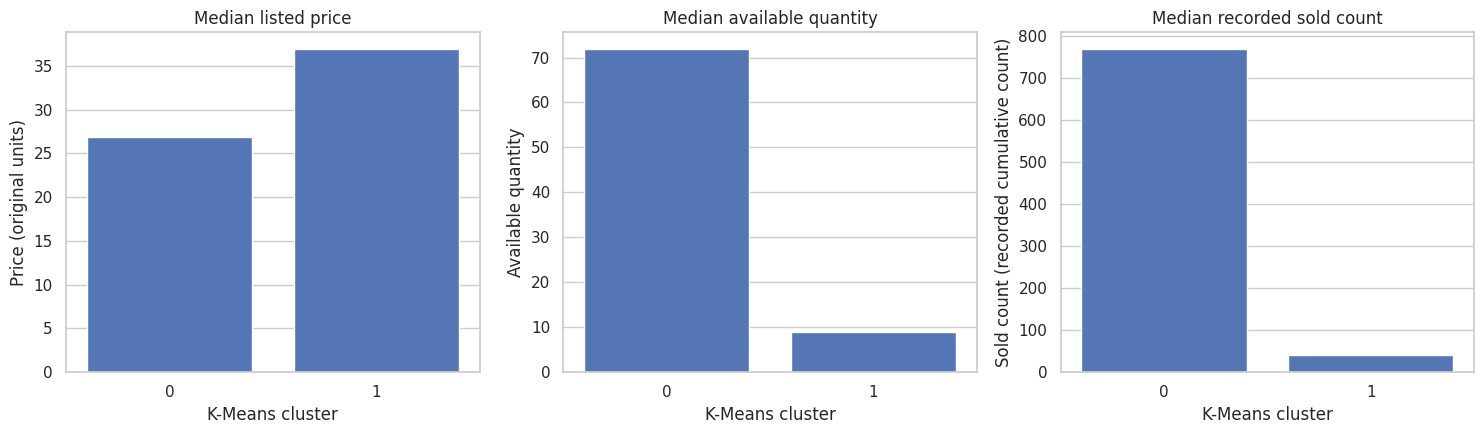

In [42]:
# Plot original-scale profiles; medians make skewed variables easier to compare.
profile_for_plot = cluster_profile.reset_index().sort_values("cluster")
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, col, title, ylabel in [
    (axes[0], "price_median", "Median listed price", "Price (original units)"),
    (axes[1], "available_median", "Median available quantity", "Available quantity"),
    (axes[2], "sold_median", "Median recorded sold count", "Sold count (recorded cumulative count)"),
]:
    sns.barplot(data=profile_for_plot, x="cluster", y=col, ax=ax, color="#4472C4")
    ax.set_title(title)
    ax.set_xlabel("K-Means cluster")
    ax.set_ylabel(ylabel)
plt.tight_layout()
plt.show()

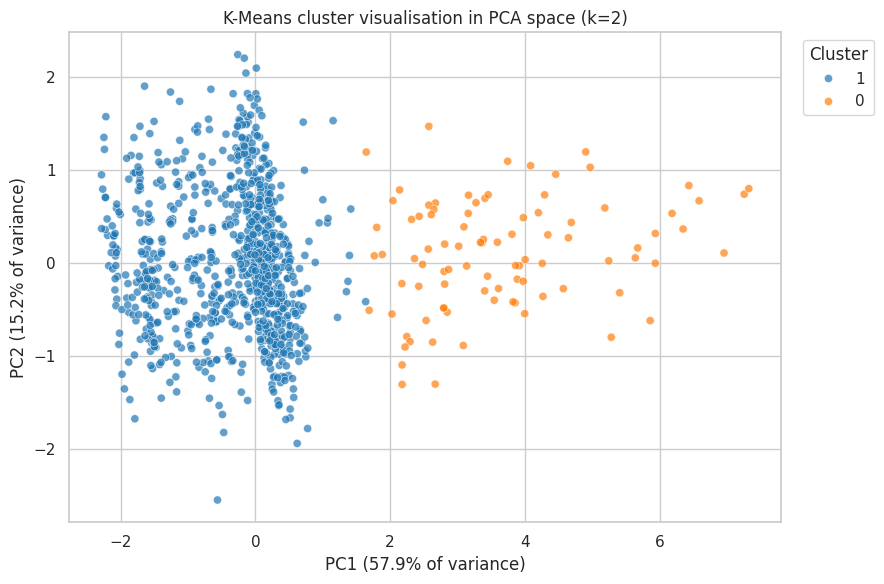

Interpret the PCA plot alongside cluster profiles; the two-dimensional projection does not show all information in the original feature matrix.


In [43]:
# Visualise the final labels in the first two PCA dimensions.
pca_plot_df = pd.DataFrame(X_pca_2d, columns=["PC1", "PC2"])
pca_plot_df["cluster"] = final_labels.astype(str)
plt.figure(figsize=(9, 6))
sns.scatterplot(data=pca_plot_df, x="PC1", y="PC2", hue="cluster", alpha=0.7, s=35, palette="tab10")
plt.title(f"K-Means cluster visualisation in PCA space (k={FINAL_K})")
plt.xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0]:.1%} of variance)")
plt.ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1]:.1%} of variance)")
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()
print("Interpret the PCA plot alongside cluster profiles; the two-dimensional projection does not show all information in the original feature matrix.")

## 14. Business interpretation and a more granular sensitivity check

A two-cluster model can be useful for an initial high-level split, but it may be too broad for some operational decisions. To make this trade-off visible, the notebook profiles a five-cluster K-Means solution (when included in the tested range) alongside the chosen model. The five-cluster solution is a sensitivity analysis, not an automatic replacement for the selected model: its internal metrics and group sizes must be weighed against its additional business detail.

In [44]:
# Cluster-category distribution as percentages within each final cluster.
category_mix = pd.crosstab(
    results["cluster"], results["cluster_category"], normalize="index"
).mul(100).round(1)
print("Category-group mix within each selected cluster (%):")
display(category_mix)

if 5 in kmeans_labels:
    sensitivity_labels = kmeans_labels[5]
    sensitivity = work.copy()
    sensitivity["cluster"] = sensitivity_labels
    profile_k5 = sensitivity.groupby("cluster").agg(
        records=("cluster", "size"),
        share_percent=("cluster", lambda s: 100 * len(s) / len(sensitivity)),
        price_median=("price", "median"),
        available_median=("available", "median"),
        sold_median=("sold", "median"),
        dominant_category=("category_clean", lambda s: s.mode().iloc[0] if not s.mode().empty else "Unknown"),
    ).sort_values("records", ascending=False)
    print("Five-cluster sensitivity profile:")
    display(profile_k5.round(2))
    row5 = kmeans_results_df.loc[kmeans_results_df["k"] == 5].iloc[0]
    print(f"Five-cluster metrics: Silhouette={row5['silhouette']:.3f}; Davies–Bouldin={row5['davies_bouldin']:.3f}; Calinski–Harabasz={row5['calinski_harabasz']:.1f}.")

Category-group mix within each selected cluster (%):


cluster_category,Eau De Cologne,Eau De Parfum,Eau De Toilette,Fragrances,Other / rare,Perfume,Unknown / missing
cluster,,,,,,,
0,8.8,18.7,69.2,0.0,3.3,0.0,0.0
1,5.4,32.2,43.6,3.5,9.5,5.5,0.3


Five-cluster sensitivity profile:


,records,share_percent,price_median,available_median,sold_median,dominant_category
cluster,,,,,,
1,308,30.8,35.49,10.0,147.0,Eau De Toilette
2,223,22.3,39.99,3.0,16.0,Eau De Toilette
3,200,20.0,74.54,10.0,37.0,Eau De Parfum
0,185,18.5,16.99,10.0,55.5,Eau De Parfum
4,84,8.4,26.92,82.5,964.5,Eau De Toilette


Five-cluster metrics: Silhouette=0.264; Davies–Bouldin=1.257; Calinski–Harabasz=420.7.


### 14.1 Data-quality audit: inconsistent and missing sales counts

The numerical `sold` field and free-text description sometimes disagree or fail to overlap. We compare them only when the text clearly matches the pattern “N sold”. A mismatch is **flagged**, not silently overwritten: a listing description may be stale and there is no independent source of truth. We also identify where the numerical value is missing but a count is available in text. Such extracted values are **not** assumed correct in the baseline. Below, an exclusion sensitivity test checks the effect of the demonstrably conflicting record.

In [45]:
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics.pairwise import euclidean_distances
from itertools import combinations
from sklearn import __version__ as sklearn_version

sold_text_parsed = pd.to_numeric(
    df_raw["text"].astype("string")
    .str.extract(r"([\d,]+)\s*sold\b", flags=re.IGNORECASE, expand=False)
    .str.replace(",", "", regex=False), errors="coerce"
)
sold_numeric = pd.to_numeric(df_raw["sold"], errors="coerce")
both_observed = sold_text_parsed.notna() & sold_numeric.notna()
sold_conflict = both_observed & (sold_text_parsed != sold_numeric)
text_only = sold_text_parsed.notna() & sold_numeric.isna()

audit = df_raw.loc[sold_conflict | text_only, ["Item_Name", "text", "sold"]].copy()
audit.insert(0, "source_row_zero_based", audit.index)
audit["sold_stated_in_text"] = sold_text_parsed.loc[audit.index]
audit["issue"] = np.where(sold_conflict.loc[audit.index], "CONFLICT", "NUMERIC MISSING")
print(f"Numeric and text sold counts comparable: {int(both_observed.sum()):,}")
print(f"Actual conflicting records: {int(sold_conflict.sum())}")
print(f"Additional text-reported counts with numeric sold missing: {int(text_only.sum())}")
display(audit)
print("Decision: retain original values in baseline; exclude conflicted record only in a sensitivity scenario.")
print("Environment: scikit-learn", sklearn_version, "; pandas", pd.__version__, "; NumPy", np.__version__)

Numeric and text sold counts comparable: 992
Actual conflicting records: 1
Additional text-reported counts with numeric sold missing: 2


,source_row_zero_based,Item_Name,text,sold,sold_stated_in_text,issue
0,0,Dior,More than 10 available / 116 sold,NaN,116,NUMERIC MISSING
4,4,Lattafa,Limited quantity available / 156 sold,NaN,156,NUMERIC MISSING
7,7,Unbranded,Last One / 6 sold,7654.0,6,CONFLICT


Decision: retain original values in baseline; exclude conflicted record only in a sensitivity scenario.
Environment: scikit-learn 1.6.1 ; pandas 2.2.3 ; NumPy 2.4.6


### 14.2 Alternative preprocessing: imputation and IQR outlier treatment

The original implementation identifies IQR outliers and retains them because extreme availability/sold counts may represent genuine high-volume listings. However, high values can still dominate distance metrics even after `log1p` and robust scaling. This experiment **compares**, rather than presumes, the effect of retaining them versus capping out-of-fence values at the non-negative 1.5×IQR fences. Capping is a *sensitivity scenario*, not a claim that censored values are correct; it preserves row count but changes magnitudes.

A further scenario replaces **median numeric imputation** with **mean numeric imputation** to examine susceptibility to skew; no strategy is asserted to be objectively correct. The discrepancy-exclusion scenario tests whether the single conflicting record materially changes the segmentation. All scenarios re-fit their own preprocessing transforms. Compare like-for-like Silhouette only for data with the same feature geometry, and use label agreement (Adjusted Rand Index) for the cross-representation sensitivity tests.

In [46]:
def build_analysis_matrix(frame, numeric_imputation="median", include_categories=True):
    """Fit an independent preprocessing pipeline on the supplied rows only."""
    num_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy=numeric_imputation)),
        ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("robust_scaler", RobustScaler()),
    ])
    transforms = [("numeric", num_pipe, numeric_features)]
    if include_categories:
        cat_pipe = Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ])
        transforms.append(("category", cat_pipe, categorical_features))
    pp = ColumnTransformer(transformers=transforms, remainder="drop", verbose_feature_names_out=False)
    columns = numeric_features + (categorical_features if include_categories else [])
    data = frame[columns].copy()
    values = pp.fit_transform(data)
    if not np.isfinite(values).all():
        raise ValueError("Preprocessing produced non-finite values.")
    return values, pp

# IQR fence treatment (cap non-negative amounts to [max(0, low fence), upper fence]).
work_capped = work.copy()
outlier_treatment = []
any_fence_outlier = pd.Series(False, index=work.index)
for field in numeric_features:
    series = pd.to_numeric(work[field], errors="coerce")
    q1, q3 = series.quantile([.25, .75])
    lower = max(0.0, q1 - 1.5*(q3-q1))
    upper = q3 + 1.5*(q3-q1)
    mask = series.notna() & ((series < lower) | (series > upper))
    any_fence_outlier |= mask
    work_capped[field] = series.clip(lower=lower, upper=upper)
    outlier_treatment.append({"field":field,"IQR_lower_cap":lower,"IQR_upper_cap":upper,
                              "flagged_values":int(mask.sum()),"max_original":series.max(),
                              "max_after_cap":work_capped[field].max()})
print("IQR sensitivity treatment details (overlapping flags may affect the same row):")
display(pd.DataFrame(outlier_treatment).round(2))
print("Unique rows with at least one IQR flag:", int(any_fence_outlier.sum()))

REFERENCE_K = 2  # requested two-cluster scenario; use the model already fitted above
assert REFERENCE_K in kmeans_labels
reference_labels = pd.Series(kmeans_labels[REFERENCE_K], index=work.index)

def fit_kmeans_scenario(label, frame, imputation="median", categories=True):
    x_case, pipeline = build_analysis_matrix(frame, imputation, categories)
    km = KMeans(n_clusters=REFERENCE_K, random_state=RANDOM_STATE, n_init=20, max_iter=500)
    labels = km.fit_predict(x_case)
    label_counts = pd.Series(labels).value_counts().sort_values(ascending=False)
    # ARI compares membership independently of the arbitrary cluster-ID order.
    ari = adjusted_rand_score(reference_labels.loc[frame.index].to_numpy(), labels)
    return {
        "scenario":label, "rows":len(frame), "n_features":x_case.shape[1],
        "silhouette":silhouette_score(x_case, labels),
        "davies_bouldin":davies_bouldin_score(x_case, labels),
        "min_cluster":int(label_counts.min()),"max_cluster":int(label_counts.max()),
        "ARI_vs_original_k2":ari,
    }, (frame, x_case, labels, pipeline)

scenario_results = []
scenario_artifacts = {}
base_sizes = pd.Series(reference_labels).value_counts()
scenario_results.append({
    "scenario":"Original: retain outliers, median, categories", "rows":len(work),
    "n_features":X.shape[1], "silhouette":silhouette_score(X, reference_labels),
    "davies_bouldin":davies_bouldin_score(X, reference_labels),
    "min_cluster":int(base_sizes.min()),"max_cluster":int(base_sizes.max()),
    "ARI_vs_original_k2":1.0,
})
for scenario, frame, strategy, use_cats in [
    ("IQR-capped values, median, categories", work_capped, "median", True),
    ("Original values, mean imputation, categories", work, "mean", True),
    ("Numerical features only, median", work, "median", False),
    ("Exclude conflicting sold-text row", work.loc[~sold_conflict].copy(), "median", True),
]:
    record, artifacts = fit_kmeans_scenario(scenario, frame, strategy, use_cats)
    scenario_results.append(record)
    scenario_artifacts[scenario] = artifacts
sensitivity_comparison = pd.DataFrame(scenario_results)
display(sensitivity_comparison.round(4))
print("Interpretation note: a higher Silhouette on differently encoded features is NOT proof of better business segments.")
print("ARI=1 means identical membership up to relabelling; ARI near 0 indicates chance-level agreement.")

IQR sensitivity treatment details (overlapping flags may affect the same row):


,field,IQR_lower_cap,IQR_upper_cap,flagged_values,max_original,max_after_cap
0,price,0.0,113.02,54,259.09,113.02
1,available,0.0,17.50,101,842.00,17.50
2,sold,0.0,790.88,136,54052.00,790.88


Unique rows with at least one IQR flag: 244


,scenario,rows,n_features,silhouette,davies_bouldin,min_cluster,max_cluster,ARI_vs_original_k2
0,"Original: retain outliers, median, categories",1000,10,0.5322,0.7425,91,909,1.0000
1,"IQR-capped values, median, categories",1000,10,0.2626,1.5277,305,695,-0.0655
2,"Original values, mean imputation, categories",1000,10,0.3863,1.0884,184,816,0.5394
3,"Numerical features only, median",1000,3,0.6070,0.6265,91,909,1.0000
4,Exclude conflicting sold-text row,999,10,0.5323,0.7425,91,908,1.0000


Interpretation note: a higher Silhouette on differently encoded features is NOT proof of better business segments.
ARI=1 means identical membership up to relabelling; ARI near 0 indicates chance-level agreement.


### 14.3 Categorical encoding: distance contribution and feature ablation

For two items with **different** one-hot categories, the squared Euclidean distance contributed by the categorical block is exactly 2. Items with the same category contribute 0 in that block. A large categorical contribution can mask meaningful differences in numeric price, stock or sold counts; conversely, excluding product type can group commercially different categories. The following computation examines how much of typical pairwise squared Euclidean distance comes from the numerical versus the categorical block. The numerical-only K-Means sensitivity row above then measures whether membership changes when categories are omitted. Neither encoding is automatically “better”; cluster actionability and stability matter.

Mean pairwise squared numerical distance (sample): 5.827
Mean pairwise squared categorical distance (sample): 1.357
Category share of *mean* pairwise squared distance: 18.9%
Ablation result (see numerical-only row in preceding comparison):


,scenario,rows,n_features,silhouette,davies_bouldin,min_cluster,max_cluster,ARI_vs_original_k2
3,"Numerical features only, median",1000,3,0.607,0.6265,91,909,1.0


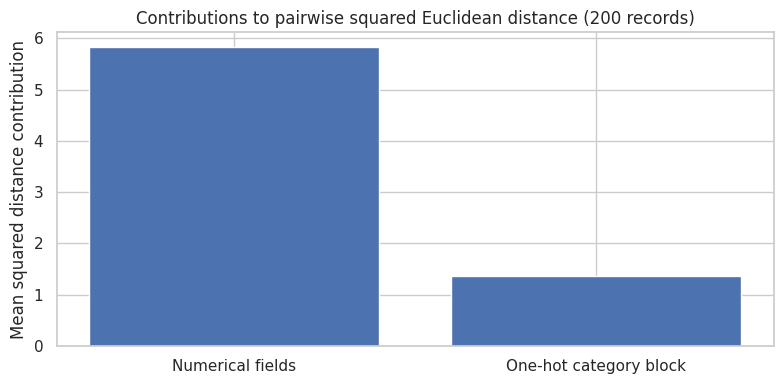

In [47]:
# The original ColumnTransformer orders numeric columns first, then category dummies.
num_count = len(numeric_features)
if X.shape[1] <= num_count:
    raise AssertionError("Expected a one-hot encoded category block in original features")
sub_ids = np.linspace(0, len(work)-1, num=min(200, len(work)), dtype=int)
num_sq = euclidean_distances(X[sub_ids,:num_count], squared=False) ** 2
cat_sq = euclidean_distances(X[sub_ids,num_count:], squared=False) ** 2
upper = np.triu_indices(len(sub_ids),k=1)
avg_num = float(num_sq[upper].mean())
avg_cat = float(cat_sq[upper].mean())
print("Mean pairwise squared numerical distance (sample):", round(avg_num,3))
print("Mean pairwise squared categorical distance (sample):", round(avg_cat,3))
print("Category share of *mean* pairwise squared distance:", f"{avg_cat/(avg_num+avg_cat):.1%}")
print("Ablation result (see numerical-only row in preceding comparison):")
display(sensitivity_comparison.loc[sensitivity_comparison['scenario'].str.contains('Numerical features only')].round(4))

fig, ax = plt.subplots(figsize=(8,4))
ax.bar(['Numerical fields','One-hot category block'], [avg_num,avg_cat])
ax.set_title('Contributions to pairwise squared Euclidean distance (200 records)')
ax.set_ylabel('Mean squared distance contribution')
plt.tight_layout(); plt.show()

### 14.4 Two clusters versus more granular business segmentation

The best internal separation score can correspond to a very uneven 2-cluster split (90.9% vs 9.1% in the submitted run), which may be sufficient for **screening unusual/high-volume listings** but not for detailed assortment, supplier or marketing decisions. Compare k=2–6 on **the same original representation**, reporting separation **and** smallest/largest cluster sizes. A five-cluster profile is already shown above. Do not select five clusters solely because there are five business groups: judge whether the smaller groups are meaningful and stable.

,k,silhouette,davies_bouldin,calinski_harabasz,minimum_group_size,maximum_group_size,sizes_descending
0,2,0.5322,0.7425,593.5327,91,909,"909, 91"
1,3,0.2544,1.3348,497.6773,86,637,"637, 277, 86"
2,4,0.2378,1.3257,449.3543,85,430,"430, 247, 238, 85"
3,5,0.2640,1.2566,420.7425,84,308,"308, 223, 200, 185, 84"
4,6,0.2580,1.2460,386.9806,28,302,"302, 221, 201, 184, 64, 28"


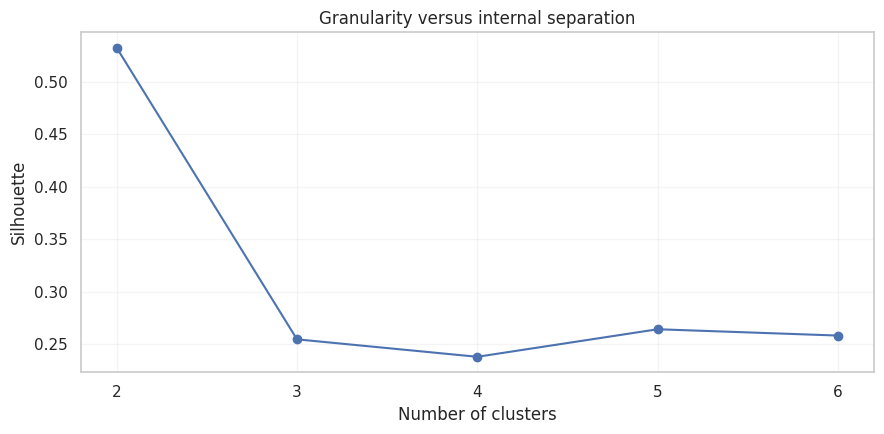

The appropriate business granularity cannot be decided solely by these internal metrics.


In [48]:
granularity_rows=[]
for k in range(2,7):
    row=kmeans_results_df.loc[kmeans_results_df['k']==k].iloc[0]
    counts=pd.Series(kmeans_labels[k]).value_counts()
    granularity_rows.append({
        'k':k,'silhouette':row['silhouette'], 'davies_bouldin':row['davies_bouldin'],
        'calinski_harabasz':row['calinski_harabasz'], 'minimum_group_size':int(counts.min()),
        'maximum_group_size':int(counts.max()), 'sizes_descending':', '.join(str(v) for v in sorted(counts,reverse=True))
    })
granularity=pd.DataFrame(granularity_rows)
display(granularity.round(4))
fig,ax=plt.subplots(figsize=(9,4.5))
ax.plot(granularity['k'],granularity['silhouette'],marker='o',label='Silhouette (higher better)')
ax.set_xticks(granularity['k']);ax.set_xlabel('Number of clusters');ax.set_ylabel('Silhouette')
ax.set_title('Granularity versus internal separation')
ax.grid(alpha=.2);plt.tight_layout();plt.show()
print('The appropriate business granularity cannot be decided solely by these internal metrics.')

### 14.5 Stability across different samples (repeatable 80% subsamples)

Silhouette/Davies–Bouldin are **internal** geometric scores. They do not tell us whether similar products remain together when the training sample changes. For each of `k=2` and `k=5`, we draw **10 independently seeded 80% subsamples without replacement**; within each repetition, preprocessing and K-Means are fitted afresh on the sampled records, then labels are assigned to the **same full set of 1,000 records** for a common comparison basis. We compute ARI against the original full-data solution and pairwise ARI between runs. A range and standard deviation communicate instability better than a single cherry-picked run.

**Interpretation boundaries:** These experiments measure assignment robustness under resampling for K-Means, not future predictive validity or external validation. Predicting the full observed set for a consistent comparison does not constitute an independent test set. ARI corrects for arbitrary label numbering and differs in purpose from Silhouette. The instability of Ward or DBSCAN under resampling is not established by this K-Means-only test.

Stability summary: full-prediction membership ARI across repeated subsamples


,k,repetitions,train_fraction,ARI_to_baseline_mean,ARI_to_baseline_sd,ARI_to_baseline_min,ARI_to_baseline_max,pairwise_ARI_mean,pairwise_ARI_min
0,2,10,0.8,0.9993,0.0023,0.9928,1.0000,0.9986,0.9928
1,5,10,0.8,0.9525,0.0316,0.8770,0.9875,0.9315,0.8541


Individual repetitions (audit trail):


,k,repetition,train_n,ARI_to_full_data_solution,smallest_predicted_group,largest_predicted_group
0,2,1,800,0.9928,92,908
1,2,2,800,1.0000,91,909
2,2,3,800,1.0000,91,909
3,2,4,800,1.0000,91,909
4,2,5,800,1.0000,91,909
5,2,6,800,1.0000,91,909
6,2,7,800,1.0000,91,909
7,2,8,800,1.0000,91,909
8,2,9,800,1.0000,91,909
9,2,10,800,1.0000,91,909


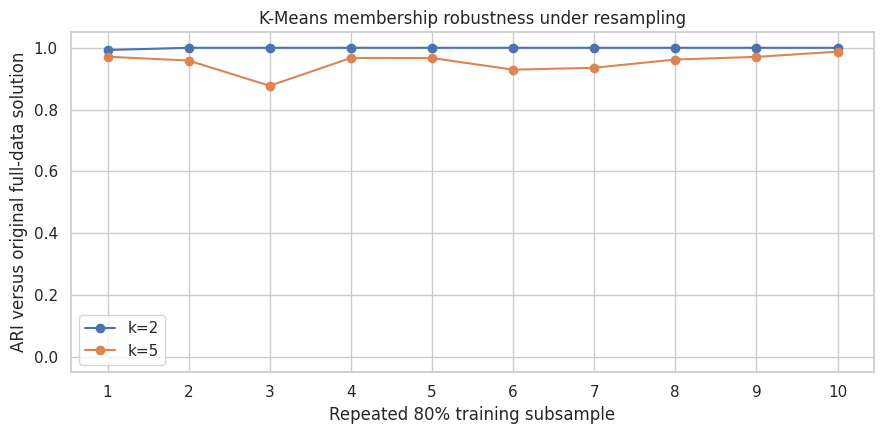

In [49]:
N_REPEATS=10
SUBSAMPLE_FRAC=.80
stability_details=[]
stability_summary_rows=[]
for k in [2,5]:
    full_labels=np.asarray(kmeans_labels[k])
    predictions=[]
    for repeat in range(N_REPEATS):
        draw=np.random.default_rng(RANDOM_STATE+100*k+repeat)
        sample_idx=np.sort(draw.choice(len(work), size=int(len(work)*SUBSAMPLE_FRAC), replace=False))
        sampled=work.iloc[sample_idx]
        x_train,pipe=build_analysis_matrix(sampled, "median", True)
        model=KMeans(n_clusters=k, random_state=RANDOM_STATE+repeat, n_init=20, max_iter=500)
        model.fit(x_train)
        full_values=pipe.transform(work[numeric_features+categorical_features])
        pred=model.predict(full_values)
        predictions.append(pred)
        counts=pd.Series(pred).value_counts()
        stability_details.append({
            'k':k, 'repetition':repeat+1, 'train_n':len(sample_idx),
            'ARI_to_full_data_solution':adjusted_rand_score(full_labels,pred),
            'smallest_predicted_group':int(counts.min()),
            'largest_predicted_group':int(counts.max()),
        })
    pairwise_aris=[adjusted_rand_score(predictions[i],predictions[j])
                   for i,j in combinations(range(N_REPEATS),2)]
    aris=[adjusted_rand_score(full_labels,p) for p in predictions]
    stability_summary_rows.append({
        'k':k, 'repetitions':N_REPEATS,'train_fraction':SUBSAMPLE_FRAC,
        'ARI_to_baseline_mean':np.mean(aris),'ARI_to_baseline_sd':np.std(aris,ddof=1),
        'ARI_to_baseline_min':np.min(aris),'ARI_to_baseline_max':np.max(aris),
        'pairwise_ARI_mean':np.mean(pairwise_aris),
        'pairwise_ARI_min':np.min(pairwise_aris),
    })
stability_detail=pd.DataFrame(stability_details)
stability_summary=pd.DataFrame(stability_summary_rows)
print('Stability summary: full-prediction membership ARI across repeated subsamples')
display(stability_summary.round(4))
print('Individual repetitions (audit trail):')
display(stability_detail.round(4))
fig,ax=plt.subplots(figsize=(9,4.5))
for k,df_k in stability_detail.groupby('k'):
    ax.plot(df_k['repetition'],df_k['ARI_to_full_data_solution'],marker='o',label=f'k={k}')
ax.set_ylim(-.05,1.05);ax.set_xticks(range(1,N_REPEATS+1))
ax.set_xlabel('Repeated 80% training subsample');ax.set_ylabel('ARI versus original full-data solution')
ax.set_title('K-Means membership robustness under resampling');ax.legend()
plt.tight_layout();plt.show()

### 14.6 Segment-specific operational actions and measurable KPIs

The original product-listing data represents a **snapshot**: `sold` lacks a defined time period, and there are no dated replenishment events, margins, product returns or stock ageing. Consequently, **neither cluster proves current demand, overstock or price elasticity**. The action plan below attaches a concrete human-review activity and an auditable KPI to **each** observed cluster. A KPI target such as “≥95%” is a **proposed pilot goal**, not a measured outcome. Assign segment-specific actions based on observed stock/sales profiles; the cluster identifier is not a business ranking.

For the uneven two-cluster solution, the small segment can support targeted manual investigation but is too small and special-purpose to substitute for a complete assortment segmentation. The larger group can be prioritised within the segment by missing data and stock age after transaction records become available.

Observed characteristics; sold is NOT units sold per day/month:


,cluster,listing_count,share_pct,price_median,available_median,sold_median_cumulative,stock_missing_pct,sales_missing_pct
1,1,909,90.9,36.99,9.0,40.0,12.21,0.88
0,0,91,9.1,26.86,72.0,771.0,0.00,0.00


,cluster,n_listings,share_pct,median_price,median_stock,median_recorded_sold,pilot_action,KPI_definition,pilot_target_not_observed,owner_and_cadence
0,1,909,90.9,36.99,9.0,40.0,Prioritise missing-stock checks and stock-age/availability review across the...,Share of reviewed listings with verified stock balance and stock-age record,PROPOSED: >=95% verified among reviewed listings within 4 weeks,Inventory/category manager; weekly review for 4 weeks
1,0,91,9.1,26.86,72.0,771.0,Prioritise verification of high recorded-sold listings; review current stock...,Share of reviewed listings with verified sold history and dated transactions,PROPOSED: >=95% verified among reviewed listings within 4 weeks,Inventory/category manager; weekly review for 4 weeks


Suggested secondary KPIs, once dated transactions are available: 30-day stockout incidence,
valid stock-record percentage, inventory ageing, gross-margin contribution, and weekly replenishment exceptions.
Baseline for these KPIs is unavailable in this snapshot; no improvement is claimed.


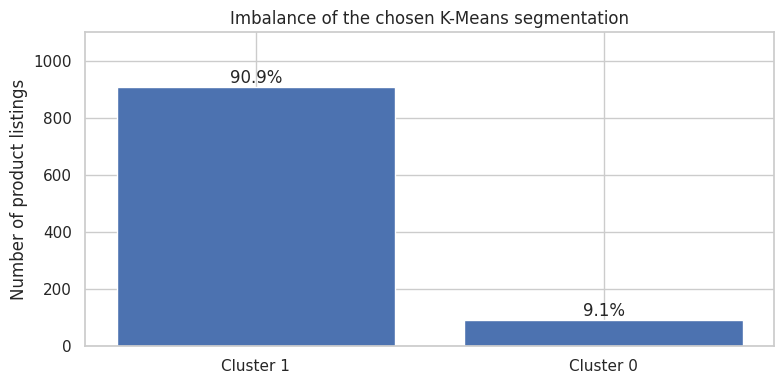

In [50]:
# Calculate observed summary from the original columns (missing values are NOT reported as observed).
segment_rows=[]
for seg_id,group in results.groupby('cluster'):
    segment_rows.append({
        'cluster':int(seg_id),'listing_count':len(group),'share_pct':100*len(group)/len(results),
        'price_median':group['price'].median(),
        'available_median':group['available'].median(),
        'sold_median_cumulative':group['sold'].median(),
        'stock_missing_pct':100*group['available'].isna().mean(),
        'sales_missing_pct':100*group['sold'].isna().mean(),
    })
segment_observations=pd.DataFrame(segment_rows).sort_values('listing_count',ascending=False)
print('Observed characteristics; sold is NOT units sold per day/month:')
display(segment_observations.round(2))

ranked=segment_observations.sort_values('sold_median_cumulative',ascending=False)
higher_sales_seg=int(ranked.iloc[0]['cluster'])
action_rows=[]
for rec in segment_observations.to_dict('records'):
    higher_sales=(int(rec['cluster'])==higher_sales_seg)
    if higher_sales:
        action='Prioritise verification of high recorded-sold listings; review current stock and sales-history integrity before replenishment changes.'
        kpi='Share of reviewed listings with verified sold history and dated transactions'
        pilot_target='PROPOSED: >=95% verified among reviewed listings within 4 weeks'
    else:
        action='Prioritise missing-stock checks and stock-age/availability review across the broader assortment before pricing or range changes.'
        kpi='Share of reviewed listings with verified stock balance and stock-age record'
        pilot_target='PROPOSED: >=95% verified among reviewed listings within 4 weeks'
    action_rows.append({
        'cluster':int(rec['cluster']), 'n_listings':int(rec['listing_count']),
        'share_pct':round(rec['share_pct'],1),
        'median_price':round(rec['price_median'],2),
        'median_stock':round(rec['available_median'],1),
        'median_recorded_sold':round(rec['sold_median_cumulative'],1),
        'pilot_action':action, 'KPI_definition':kpi, 'pilot_target_not_observed':pilot_target,
        'owner_and_cadence':'Inventory/category manager; weekly review for 4 weeks'
    })
action_plan=pd.DataFrame(action_rows)
display(action_plan)
print('Suggested secondary KPIs, once dated transactions are available: 30-day stockout incidence,')
print('valid stock-record percentage, inventory ageing, gross-margin contribution, and weekly replenishment exceptions.')
print('Baseline for these KPIs is unavailable in this snapshot; no improvement is claimed.')

fig,ax=plt.subplots(figsize=(8,4))
ax.bar([f"Cluster {int(v)}" for v in segment_observations['cluster']], segment_observations['listing_count'])
for i,row in enumerate(segment_observations.itertuples()):
    ax.text(i,row.listing_count+12,f"{row.share_pct:.1f}%",ha='center')
ax.set_ylabel('Number of product listings');ax.set_ylim(0,1100)
ax.set_title('Imbalance of the chosen K-Means segmentation')
plt.tight_layout();plt.show()

### 14.7 Critical interpretation of the newly executed tests

The following findings were **calculated from the uploaded 1,000-row CSV in this revised notebook**, not inferred from general clustering theory:

- **Sales integrity:** Of 992 records with both parseable text and numeric sold counts, **one conflicts**. At source row index 7, the text says **6 sold** but the numeric column records **7,654**. Two more rows have parseable text counts but missing numeric `sold`. Because the source of truth is unresolved, the baseline does not overwrite those observations. Excluding the one conflict left the two-cluster membership unchanged on the **999 comparable observations** (ARI **1.000**).
- **Outlier vulnerability:** The union of IQR flags affects **244 unique listings**. Capping flagged numerical magnitudes at IQR fences changes the two-cluster sizes to **695 and 305**, reduces Silhouette from **0.5322** to **0.2626**, and gives ARI **−0.0655** versus the baseline. Thus, the apparently clear original split is **highly sensitive to this aggressive capping policy**. This is a warning about robustness, *not* grounds to cap genuine high-value listings automatically.
- **Imputation matters:** Switching numerical imputation from the median to the mean produces **816/184** groups and ARI **0.5394** versus the baseline. This supports retaining the median as a cautious starting point in the skewed dataset, but the missing-stock mechanism still needs investigation.
- **Categorical-feature ablation:** Removing category dummies produces the **same 909/91 partition** up to cluster relabelling (ARI **1.000**); Silhouette changes from **0.5322** to **0.6070**. These Silhouettes are evaluated in different feature spaces, so the higher score does **not** on its own prove the numeric-only representation is commercially superior. The categorical block contributes about **18.9%** of mean squared pairwise distance in the 200-record audit sample, even though it does not change the two-cluster membership here.
- **Business detail:** `k=5` produces group sizes **308, 223, 200, 185 and 84**, but its Silhouette is only **0.2640**, versus **0.5322** for `k=2`. The business must balance added detail against weaker separation; either choice requires domain review.
- **Assignment stability:** Over ten independently generated 80%-sample refits, mean ARI against the original solution is **0.9993** for `k=2` (minimum **0.9928**) and **0.9525** for `k=5` (minimum **0.8770**). The two-group solution is therefore very stable **under this particular resampling test**, while remaining sensitive to some preprocessing decisions. **Stability does not establish business usefulness or validity of cumulative sales figures.**

**Overall decision:** The 2-cluster K-Means result remains a **provisional triage/screening baseline**, not an automated replenishment or marketing policy. Its 909/91 imbalance, dependence on imputation and outlier policy, and lack of dated sales records make stakeholder validation and a monitored pilot necessary. K-Means, Ward and DBSCAN results should be interpreted as alternative descriptions of this snapshot, not ground truth.

### 14.8 Saved evidence for the 3,000-word critical report

Run this cell to export the exact recalculated sensitivity, granularity, stability and segment figures/tables in a companion `analysis_outputs/` folder. The report should use the table values **from the executed outputs**, not from memory. The outputs do not claim a published GitHub repository or Turnitin check; those remain separate authorised steps.

In [51]:
OUTPUT_DIR=Path.cwd()/"analysis_outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
exports={
    '01_data_quality_issues.csv':audit,
    '02_iqr_fence_treatment.csv':pd.DataFrame(outlier_treatment),
    '03_preprocessing_feature_sensitivity.csv':sensitivity_comparison,
    '04_cluster_count_granularity.csv':granularity,
    '05_resampling_stability_each_run.csv':stability_detail,
    '06_resampling_stability_summary.csv':stability_summary,
    '07_observed_cluster_profiles.csv':segment_observations,
    '08_proposed_operational_kpis.csv':action_plan,
    '09_original_model_comparison.csv':comparison,
}
for name,table in exports.items():
    table.to_csv(OUTPUT_DIR/name,index=False)
print('Exported', len(exports),'tables to',OUTPUT_DIR)
print('Dataset file used:',DATA_PATH.name)
print('Reproduce with the notebook + original CSV + requirements; use a real GitHub URL only after publication.')

Exported 9 tables to /content/analysis_outputs
Dataset file used: Sales-[5444].csv
Reproduce with the notebook + original CSV + requirements; use a real GitHub URL only after publication.


## 15. Business findings and measurable action plan

The tables above distinguish the large 909/91-style broad segmentation from potentially more actionable but less geometrically separated alternatives. Use **observed** cluster medians and sizes from the executed outputs, not an assumed sales rate. A product's cumulative `sold` count cannot be converted into monthly demand without dated transactions.

The additional **proposed** intervention/KPI table in section 14.6 gives actions for each observed cluster. Recommended implementation is a four-week, human-reviewed pilot with monitoring by inventory/category managers. These targets are *proposed thresholds*, not results already achieved. Verify listing dates, stock movements, margins and return rates before price or replenishment decisions. The model is for screening and prioritisation, not autonomous stock or pricing changes.

In [52]:
# Create a compact results summary that can be reused in the written report.
final_summary = pd.DataFrame({
    "item": [
        "Dataset records", "Dataset columns", "Exact duplicate rows",
        "Selected K-Means cluster count", "K-Means Silhouette",
        "K-Means Davies–Bouldin", "K-Means Calinski–Harabasz",
        "DBSCAN epsilon", "DBSCAN min_samples", "DBSCAN clusters excluding noise",
        "DBSCAN noise percentage", "PCA variance explained by first two components"
    ],
    "result": [
        len(df_raw), df_raw.shape[1], int(df_raw.duplicated().sum()),
        FINAL_K, round(float(best_kmeans_row["silhouette"]), 4),
        round(float(best_kmeans_row["davies_bouldin"]), 4),
        round(float(best_kmeans_row["calinski_harabasz"]), 2),
        best_dbscan_key[0], best_dbscan_key[1], int(dbscan_best_row["clusters_excluding_noise"]),
        round(float(dbscan_best_row["noise_percent"]), 2),
        round(float(pca_2d.explained_variance_ratio_.sum()), 4)
    ]
})
display(final_summary)

print("Cluster profile (rounded) for report drafting:")
display(cluster_profile.round(2))

,item,result
0,Dataset records,1000.0000
1,Dataset columns,10.0000
2,Exact duplicate rows,0.0000
3,Selected K-Means cluster count,2.0000
4,K-Means Silhouette,0.5322
5,K-Means Davies–Bouldin,0.7425
6,K-Means Calinski–Harabasz,593.5300
7,DBSCAN epsilon,0.5000
8,DBSCAN min_samples,15.0000
9,DBSCAN clusters excluding noise,4.0000


Cluster profile (rounded) for report drafting:


,records,share_percent,price_median,price_mean,available_median,sold_median,sold_75th_percentile,dominant_category
cluster,,,,,,,,
1,909,90.9,36.99,48.15,9.0,40.0,217.0,Eau De Toilette
0,91,9.1,26.86,29.38,72.0,771.0,2026.5,Eau De Toilette


## 16. Critical evaluation and limitations

The results need to be interpreted within the limits of the supplied data and chosen features:

- **Cumulative sales ambiguity:** `sold` is a recorded count, but there is no defined observation window. It is not valid to call it weekly or monthly demand without another source.
- **Missing values:** median imputation keeps the rows available for model comparison but reduces the information available for records with missing price, stock or sold counts. The cluster profile reports statistics from observed original values and can therefore have differing non-null counts between features.
- **Outliers:** log transformation and robust scaling reduce the influence of extreme values but do not eliminate all outlier effects. IQR flags are reviewed rather than removed automatically.
- **Feature engineering:** price, stock, recorded sold count and broad category are only a subset of possible useful features. Seller, product text, location and update time were excluded from the baseline to avoid high-cardinality or duplicate information; future work could engineer them carefully and test whether they improve stable, actionable segmentation.
- **Cluster-size imbalance and granularity:** the selected two-cluster K-Means model should be checked for imbalance. A small segment can be operationally important but may make the overall segmentation too broad for some decisions. The five-cluster sensitivity profile illustrates the trade-off: more detailed groups have weaker internal separation scores in this run. The preferred level of detail should be validated with business stakeholders.
- **Internal metrics:** Silhouette, Davies–Bouldin and Calinski–Harabasz measure geometric separation/compactness, not commercial value. DBSCAN scores are calculated only on non-noise records and are therefore not a fair direct numerical comparison with methods that assign every record.
- **Distance-based methods:** results depend on scaling, encoding, transformations and parameter choices. Alternative preprocessing and feature weights should be tested as sensitivity checks.
- **No causal conclusions:** clustering reveals patterns of association in this snapshot. It does not establish that price, stock or category causes sales outcomes.
- **Validation with users:** before operational deployment, validate the cluster profiles with category/inventory managers and refresh the model with current transactional data.

These limitations should be discussed explicitly in Task 2. Do not hide an inconvenient metric or overstate the findings.

## 17. Conclusion

This notebook establishes a reproducible clustering workflow for the supplied e-commerce product-listing dataset. It investigates missing values, category inconsistencies, potential discrepancies between numeric and text-based sold counts, and extreme values. It then prepares a consistent feature matrix combining transformed/scaled numeric variables with one-hot-encoded category groups and evaluates K-Means, agglomerative Hierarchical Clustering and DBSCAN.

The selected K-Means solution should be reported with its actual validation metrics and cluster profiles displayed above. Hierarchical Clustering provides a comparison, while DBSCAN is assessed partly for its ability to identify dense groups and noise. The business recommendation must follow the observed profile differences and acknowledge that the dataset does not define a sales time window, margins, stock age or causal relationships. A model that is technically separated but not actionable should not be deployed without stakeholder validation.

## 18. References (Harvard style)

Use the university/module's required referencing guidance for the final Word/PDF submission. The following sources support the methods used in this notebook:

- Ester, M., Kriegel, H.-P., Sander, J. and Xu, X. (1996) ‘A density-based algorithm for discovering clusters in large spatial databases with noise’, *Proceedings of the Second International Conference on Knowledge Discovery and Data Mining*, pp. 226–231.
- Jolliffe, I.T. and Cadima, J. (2016) ‘Principal component analysis: a review and recent developments’, *Philosophical Transactions of the Royal Society A: Mathematical, Physical and Engineering Sciences*, 374(2065), 20150202.
- MacQueen, J. (1967) ‘Some methods for classification and analysis of multivariate observations’, in *Proceedings of the Fifth Berkeley Symposium on Mathematical Statistics and Probability*, Vol. 1, pp. 281–297.
- Pedregosa, F. et al. (2011) ‘Scikit-learn: Machine learning in Python’, *Journal of Machine Learning Research*, 12, pp. 2825–2830.
- Rousseeuw, P.J. (1987) ‘Silhouettes: a graphical aid to the interpretation and validation of cluster analysis’, *Journal of Computational and Applied Mathematics*, 20, pp. 53–65.
- Ward, J.H. (1963) ‘Hierarchical grouping to optimize an objective function’, *Journal of the American Statistical Association*, 58(301), pp. 236–244.

**Dataset:** Supplied assessment file, `Machin Learning Sales-[5444].csv` (provided with the COM7022 assignment materials).

## 19. Reproducibility and final submission checks

- [ ] Add the correct student ID and module details.
- [ ] Place the original permitted CSV beside this notebook and choose **Run All**; every code cell should execute without errors.
- [ ] Check all newly generated figures/tables, and verify the Word report cites the *executed* results (not the original pre-revision results if different).
- [ ] Submit the **separate 3,000-word critical report** with clearly labelled Task 1 and Task 2 sections, figures, tables and Harvard references under the lecturer's word-count rules.
- [ ] Provide an **accessible GitHub repository link** with `.ipynb`, `README.md`, `requirements.txt`, analysis outputs and the data only if allowed. Do not insert a fabricated URL; publish under an authorised account and paste the real repository link into the report.
- [ ] Obtain any **genuine Turnitin report** through the university's licensed service. This notebook cannot produce one.
- [ ] Recheck the numerical/text sales discrepancy, sensitivity assumptions and whether operational targets are explicitly labelled proposed rather than observed.

To reproduce: use Python 3.11+ with the packages listed in `requirements.txt`; keep the supplied CSV in the notebook directory. The notebook writes compact new test results to `analysis_outputs/` when executed.